# Лабораторная работа №7: Автоматическая разметка изображений с помощью VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Определить schema аннотации.
- Получить структурированные ответы VLM с retry.
- Проверить выборку человеком и обучить downstream baseline.


## Теоретическая часть

Авторазметка — это data pipeline: schema → generation → parsing → validation → confidence proxy → human audit. Нельзя терять сырой ответ модели: он нужен для трассировки ошибок и повторной обработки.


### Математическая постановка

Agreement для поля можно оценивать Cohen $\kappa=(p_o-p_e)/(1-p_e)$. Для редких классов важнее class-wise precision/recall, чем общая accuracy.


### Материалы

- [JSON Schema](https://json-schema.org/learn/getting-started-step-by-step)
- [Pydantic](https://docs.pydantic.dev/latest/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Полный эксперимент (`FAST_DEV_RUN=False`) требует GPU и ручной экспертизы captions. Классы CIFAR-10 служат проверяемым эталоном, а не ответами VLM. Установите torchvision, transformers, accelerate, bitsandbytes, pydantic, scikit-learn. В Colab сохраните `artifacts/` на Drive до начала инференса. FAST_DEV_RUN проверяет загрузку данных и схему без фиктивных метрик.

In [1]:
# ===== Настройка: окружение, конфиг, VLM =====
# Если чего-то нет: %pip install -q pydantic scikit-learn torchvision accelerate bitsandbytes truststore
import os, json, time, random
from pathlib import Path
import numpy as np

try:
    import truststore; truststore.inject_into_ssl()
    print("truststore ✔")
except Exception as e:
    print("truststore пропущен:", e)
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

SEED = 42
FAST_DEV_RUN = False   # True: механика на малой выборке (НЕ отчётный запуск); потом поставить False
RUN_BONUS = True      # бонусное мини-исследование

ARTIFACTS = Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
IMG_DIR = ARTIFACTS / "images"; IMG_DIR.mkdir(exist_ok=True)

if FAST_DEV_RUN:
    N_PER_CLASS_TRAIN, N_PER_CLASS_TEST, AUDIT_N, BONUS_PER_CLASS = 1, 1, 4, 1
else:
    N_PER_CLASS_TRAIN, N_PER_CLASS_TEST, AUDIT_N, BONUS_PER_CLASS = 5, 5, 20, 2

random.seed(SEED); np.random.seed(SEED)

def save_json(name, data):
    (ARTIFACTS / name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

def append_jsonl(path, rec):
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()

import torch
from PIL import Image

HAVE_GPU = torch.cuda.is_available()
if not HAVE_GPU:
    if FAST_DEV_RUN:
        print("Нет GPU: VLM-этапы будут пропущены (FAST проверяет данные и схему)")
    else:
        raise RuntimeError("Полный режим требует GPU")

if HAVE_GPU:
    from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig
    MODEL_ID = os.getenv("CV_VLM_MODEL", "Qwen/Qwen2.5-VL-3B-Instruct")
    quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quant, device_map="auto").eval()
    print("VLM:", MODEL_ID, "| GPU:", torch.cuda.get_device_name(0))

def infer_image(path, prompt, max_new_tokens=96):
    """Один вызов VLM по пути к картинке -> (сырой текст, время генерации)."""
    img = Image.open(path).convert("RGB")
    messages = [{"role": "user", "content": [{"type": "image", "image": img}, {"type": "text", "text": prompt}]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text], images=[img], return_tensors="pt").to(model.device)
    t0 = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    dt = time.time() - t0
    ans = processor.batch_decode(out[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()
    return ans, dt

truststore ✔


The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

VLM: Qwen/Qwen2.5-VL-3B-Instruct | GPU: NVIDIA GeForce GTX 1050 Ti


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Источник и классы

*Вес: 1 балл.*

**Постановка.** Этап «источник и классы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Загрузите раздельные части CIFAR-10 и зафиксируйте перечень классов.
2. Сохраните и предъявите train/test CIFAR-10 и список классов.

**Результат.** train/test CIFAR-10 и список классов.

**Критерий принятия.** Задание считается принятым, если train/test CIFAR-10 и список классов получены из фактических входов этого этапа и доступны для проверки.

In [2]:
# ===== Этап 1. CIFAR-10 train/test + список классов =====
import torchvision

train_ds = torchvision.datasets.CIFAR10("data", train=True, download=True)
test_ds  = torchvision.datasets.CIFAR10("data", train=False, download=True)
CLASSES = train_ds.classes
assert len(CLASSES) == 10 and len(train_ds) == 50000 and len(test_ds) == 10000

save_json("dataset_info.json", {
    "dataset": "CIFAR-10", "train_size": len(train_ds), "test_size": len(test_ds),
    "classes": CLASSES, "n_classes": len(CLASSES), "image_size": "32x32x3",
    "torchvision": torchvision.__version__,
})
print("Классы:", CLASSES)
print(f"train={len(train_ds)}, test={len(test_ds)} -> artifacts/dataset_info.json")

Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
train=50000, test=10000 -> artifacts/dataset_info.json


### Стратифицированный отбор изображений

*Вес: 1 балл.*

**Постановка.** Этап «стратифицированный отбор изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите равное число изображений каждого класса в train и test; запишите постоянные ID и пути.
2. Сохраните и предъявите пути и идентификаторы изображений по классам.

**Результат.** пути и идентификаторы изображений по классам.

**Критерий принятия.** Задание считается принятым, если пути и идентификаторы изображений по классам получены из фактических входов этого этапа и доступны для проверки.

In [3]:
# ===== Этап 2. Равное число изображений каждого класса, фиксируем ID и пути =====
def stratified_select(ds, n_per_class, split):
    targets = np.array(ds.targets)
    rng = random.Random(SEED + (0 if split == "train" else 1))  # детерминированный отбор
    sel = {}
    for ci, cname in enumerate(CLASSES):
        idx = np.where(targets == ci)[0].tolist()
        rng.shuffle(idx)
        sel[cname] = [{"id": f"{split}_{i}", "idx": int(i)} for i in sorted(idx[:n_per_class])]
    return sel

selection = {"train": stratified_select(train_ds, N_PER_CLASS_TRAIN, "train"),
             "test":  stratified_select(test_ds,  N_PER_CLASS_TEST,  "test")}

# PNG на диск: artifacts/images/<split>/<class>/<id>.png
for split, ds in [("train", train_ds), ("test", test_ds)]:
    for cname, items in selection[split].items():
        d = IMG_DIR / split / cname; d.mkdir(parents=True, exist_ok=True)
        for it in items:
            ds[it["idx"]][0].save(d / f"{it['id']}.png")

sel_flat = {split: {c: [{"id": it["id"], "path": str(IMG_DIR / split / c / f"{it['id']}.png")}
                        for it in items] for c, items in per.items()}
            for split, per in selection.items()}
save_json("selection.json", {"n_per_class": {"train": N_PER_CLASS_TRAIN, "test": N_PER_CLASS_TEST},
                             "by_split_class": sel_flat})
n_total = sum(len(v) for p in selection.values() for v in p.values())
print(f"Отобрано {n_total} изображений ({N_PER_CLASS_TRAIN} train / {N_PER_CLASS_TEST} test на класс)")
print("PNG -> artifacts/images/, ID и пути -> artifacts/selection.json")

Отобрано 100 изображений (5 train / 5 test на класс)
PNG -> artifacts/images/, ID и пути -> artifacts/selection.json


### Манифест изображений

*Вес: 1 балл.*

**Постановка.** Этап «манифест изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Проверьте объём выборок и сохраните манифест с эталонными метками, не передавая их VLM.
2. Сохраните и предъявите artifacts/images.jsonl без пересечения train/test.

**Результат.** artifacts/images.jsonl без пересечения train/test.

**Критерий принятия.** Задание считается принятым, если artifacts/images.jsonl без пересечения train/test получены из фактических входов этого этапа и доступны для проверки.

In [4]:
# ===== Этап 3. Манифест с эталонными метками (метки НЕ уходят в VLM) =====
manifest = []
for split, ds in [("train", train_ds), ("test", test_ds)]:
    for ci, cname in enumerate(CLASSES):
        for it in selection[split][cname]:
            manifest.append({"id": it["id"], "split": split, "class_name": cname, "label": ci,
                             "path": str(IMG_DIR / split / cname / f"{it['id']}.png")})

ids_tr = {m["id"] for m in manifest if m["split"] == "train"}
ids_te = {m["id"] for m in manifest if m["split"] == "test"}
assert not (ids_tr & ids_te), "Пересечение train/test!"
(ARTIFACTS / "images.jsonl").write_text(
    "\n".join(json.dumps(m, ensure_ascii=False) for m in manifest), encoding="utf-8")
print(f"Манифест: {len(manifest)} записей -> artifacts/images.jsonl")
print(f"train={len(ids_tr)}, test={len(ids_te)}, пересечение={len(ids_tr & ids_te)}")

Манифест: 100 записей -> artifacts/images.jsonl
train=50, test=50, пересечение=0


### Схема и парсер VLM-ответа

*Вес: 1 балл.*

**Постановка.** Этап «схема и парсер vlm-ответа» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Определите строгую схему class_name, caption, uncertain; отклоняйте незнакомые классы и пустые описания.
2. Сохраните и предъявите типизированная схема, prompt и функция parse.

**Результат.** типизированная схема, prompt и функция parse.

**Критерий принятия.** Задание считается принятым, если типизированная схема, prompt и функция parse получены из фактических входов этого этапа и доступны для проверки.

In [5]:
# ===== Этап 4. Строгая схема (pydantic), промпт и парсер =====
import re
from typing import Literal
from pydantic import BaseModel, Field, ValidationError

class Annotation(BaseModel):
    class_name: Literal[tuple(CLASSES)]   # незнакомый класс -> ValidationError
    caption: str = Field(min_length=15)   # пустые/огрызки описаний отклоняем
    uncertain: bool = False

PROMPT = (
    'Look at the image. Return ONLY a JSON object with exactly these keys:\n'
    '{"class_name": "<one of: %s>", "caption": "<1-2 English sentences describing the image>", "uncertain": <true|false>}\n'
    "class_name must be exactly one of the listed classes. If unsure, pick the closest one and set uncertain=true."
) % ", ".join(CLASSES)

JSON_RE = re.compile(r"\{.*\}", re.DOTALL)

def parse_annotation(raw: str):
    """Сырой ответ -> (Annotation|None, ошибка|None). Никогда не бросает исключений."""
    m = JSON_RE.search(raw)
    if not m:
        return None, "no_json_object"
    try:
        data = json.loads(m.group(0))
    except json.JSONDecodeError as e:
        return None, f"json_decode: {e}"
    try:
        return Annotation.model_validate(data), None
    except ValidationError as e:
        return None, f"schema: {e.errors()[0]['msg']}"

# самопроверка парсера
ok, _  = parse_annotation('{"class_name": "cat", "caption": "A photo of a single cat sitting on grass.", "uncertain": false}')
bad, err = parse_annotation('{"class_name": "puppy", "caption": "A puppy plays with a ball.", "uncertain": false}')
print("валидный:", bool(ok), "| незнакомый класс отклонён:", bad is None, f"({err})")
save_json("schema_and_prompt.json", {"schema": Annotation.model_json_schema(), "prompt": PROMPT})

валидный: True | незнакомый класс отклонён: True (schema: Input should be 'airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship' or 'truck')


### Возобновляемое получение аннотаций

*Вес: 1 балл.*

**Постановка.** Этап «возобновляемое получение аннотаций» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вызовите Qwen2.5-VL для каждого изображения, повторяйте ошибочный JSON до трёх раз и сохраняйте исходные ответы по ID.
2. Сохраните и предъявите artifacts/annotations.jsonl с сырыми ответами и временем.

**Результат.** artifacts/annotations.jsonl с сырыми ответами и временем.

**Критерий принятия.** Задание считается принятым, если artifacts/annotations.jsonl с сырыми ответами и временем получены из фактических входов этого этапа и доступны для проверки.

In [6]:
# ===== Этап 5. Аннотации Qwen2.5-VL: retry<=3 на ошибочный JSON, сырые ответы сохраняются =====
ANN_PATH = ARTIFACTS / "annotations.jsonl"

if HAVE_GPU:
    done = {}
    if ANN_PATH.exists():
        for line in ANN_PATH.read_text(encoding="utf-8").splitlines():
            if line.strip():
                r = json.loads(line); done[r["id"]] = r
        print(f"resume: уже готово {len(done)} аннотаций, досыпаем только новые")

    retries_total = 0
    for m in manifest:
        if m["id"] in done:
            continue
        raw, dt = infer_image(m["path"], PROMPT)
        ann, err = parse_annotation(raw)
        attempts = 1
        while ann is None and attempts < 3:      # ошибочный JSON -> повтор, максимум 3 попытки
            raw, dt2 = infer_image(m["path"], PROMPT)
            dt += dt2; attempts += 1
            ann, err = parse_annotation(raw)
        retries_total += attempts - 1
        rec = {"id": m["id"], "split": m["split"], "path": m["path"],
               "raw_response": raw, "parse_error": err, "valid": ann is not None,
               "parsed": ann.model_dump() if ann else None,
               "attempts": attempts, "latency_s": round(dt, 2),
               "ts": time.strftime("%Y-%m-%d %H:%M:%S")}
        append_jsonl(ANN_PATH, rec); done[m["id"]] = rec
        print(f"[{len(done)}/{len(manifest)}] {m['id']}: "
              f"{'OK ' + ann.class_name if ann else 'FAIL ' + str(err)} ({attempts} попыт., {dt:.1f}s)")

    n_valid = sum(1 for r in done.values() if r["valid"])
    print(f"\nИтого: {len(done)} аннотаций, валидных {n_valid} ({n_valid/len(done):.0%}), повторов: {retries_total}")
else:
    print("Нет GPU -> этап пропущен (FAST)")

resume: уже готово 100 аннотаций, досыпаем только новые

Итого: 100 аннотаций, валидных 98 (98%), повторов: 0


### Проверка формата без GPU

*Вес: 1 балл.*

**Постановка.** Этап «проверка формата без gpu» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. В smoke-режиме проверьте только разбор валидного ответа, не вычисляя качество VLM.
2. Сохраните и предъявите проверка JSON-схемы в smoke-режиме.

**Результат.** проверка JSON-схемы в smoke-режиме.

**Критерий принятия.** Задание считается принятым, если проверка JSON-схемы в smoke-режиме получены из фактических входов этого этапа и доступны для проверки.

In [7]:
# ===== Этап 6. Smoke-проверка парсера (только формат, не качество VLM) =====
samples = [
    ('{"class_name": "cat", "caption": "A photo of a single cat sitting on grass.", "uncertain": false}', True),
    ('Вот ответ: {"class_name": "ship", "caption": "A large ship sails on open water near the port.", "uncertain": false}', True),
    ('{"class_name": "puppy", "caption": "A puppy plays with a ball in the yard.", "uncertain": false}', False),
    ('{"class_name": "frog", "caption": "Жаба", "uncertain": false}', False),
    ('no json here at all', False),
]
smoke = []
for raw, expect in samples:
    ann, err = parse_annotation(raw)
    passed = (ann is not None) == expect
    smoke.append({"raw": raw, "valid": ann is not None, "expected": expect, "passed": passed, "error": err})
    print(("PASS" if passed else "FAIL"), "| valid =", ann is not None, "|", err or "ok", "|", raw[:55])

save_json("smoke_parse.json", {"all_passed": all(s["passed"] for s in smoke), "cases": smoke})
print("\nИтог smoke:", "ВСЕ ТЕСТЫ ПРОЙДЕНЫ" if all(s["passed"] for s in smoke) else "ЕСТЬ ПРОБЛЕМЫ")

PASS | valid = True | ok | {"class_name": "cat", "caption": "A photo of a single c
PASS | valid = True | ok | Вот ответ: {"class_name": "ship", "caption": "A large s
PASS | valid = False | schema: Input should be 'airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship' or 'truck' | {"class_name": "puppy", "caption": "A puppy plays with 
PASS | valid = False | schema: String should have at least 15 characters | {"class_name": "frog", "caption": "Жаба", "uncertain": 
PASS | valid = False | no_json_object | no json here at all

Итог smoke: ВСЕ ТЕСТЫ ПРОЙДЕНЫ


### Покрытие и матрица ошибок

*Вес: 1 балл.*

**Постановка.** Этап «покрытие и матрица ошибок» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Подсчитайте coverage, precision/recall и матрицу ошибок только по настоящим ответам модели на test.
2. Сохраните и предъявите artifacts/quality.json по ответам VLM.

**Результат.** artifacts/quality.json по ответам VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/quality.json по ответам VLM получены из фактических входов этого этапа и доступны для проверки.

In [8]:
# ===== Этап 7. Coverage, precision/recall, матрица ошибок (только валидные ответы VLM, test) =====
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, cohen_kappa_score

if ANN_PATH.exists():
    by_id = {r["id"]: r for r in [json.loads(l) for l in ANN_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]}
    test_rows = [m for m in manifest if m["split"] == "test"]
    answered = [m for m in test_rows if m["id"] in by_id and by_id[m["id"]]["valid"]]

    y_true = [m["label"] for m in answered]
    y_pred = [CLASSES.index(by_id[m["id"]]["parsed"]["class_name"]) for m in answered]
    p, r, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=range(10), zero_division=0)
    acc = float(np.mean(np.array(y_true) == np.array(y_pred)))
    try:
        kappa = float(cohen_kappa_score(y_true, y_pred))
    except Exception:
        kappa = None
    errors = [{"id": m["id"], "gt": m["class_name"], "pred": by_id[m["id"]]["parsed"]["class_name"],
               "uncertain": by_id[m["id"]]["parsed"]["uncertain"]}
              for m in answered if by_id[m["id"]]["parsed"]["class_name"] != m["class_name"]]

    save_json("quality.json", {
        "split": "test", "n_test": len(test_rows), "n_valid": len(answered),
        "coverage": round(len(answered) / len(test_rows), 3), "accuracy": round(acc, 3),
        "cohen_kappa": round(kappa, 3) if kappa is not None else None,
        "per_class": {CLASSES[i]: {"precision": round(float(p[i]), 3), "recall": round(float(r[i]), 3),
                                   "f1": round(float(f1[i]), 3), "support": int(sup[i])} for i in range(10)},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=range(10)).tolist(),
        "confusion_classes": CLASSES, "n_errors": len(errors), "errors": errors,
        "note": "учтены только валидные ответы (парсинг + схема пройдены)",
    })
    print(f"coverage={len(answered)/len(test_rows):.2f} ({len(answered)}/{len(test_rows)})  "
          f"accuracy={acc:.2f}  kappa={kappa if kappa is None else round(kappa, 2)}")
    worst = sorted(((CLASSES[i], round(float(r[i]), 2)) for i in range(10)), key=lambda kv: kv[1])[:3]
    print("worst recall:", worst)
else:
    print("annotations.jsonl нет -> сначала этап 5")

coverage=0.98 (49/50)  accuracy=0.73  kappa=0.7
worst recall: [('cat', 0.4), ('deer', 0.4), ('frog', 0.4)]


### Экспертная оценка описаний

*Вес: 1 балл.*

**Постановка.** Этап «экспертная оценка описаний» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Соберите отдельные экспертные оценки подписей и не подменяйте их пустым файлом.
2. Сохраните и предъявите artifacts/human_audit.jsonl с экспертными записями.

**Результат.** artifacts/human_audit.jsonl с экспертными записями.

**Критерий принятия.** Задание считается принятым, если artifacts/human_audit.jsonl с экспертными записями получены из фактических входов этого этапа и доступны для проверки.

In [9]:
# ===== Этап 8. Каркас human_audit.jsonl (identity-заполнение: уже размеченное не трогаем) =====
AUDIT_PATH = ARTIFACTS / "human_audit.jsonl"

if ANN_PATH.exists():
    recs = [json.loads(l) for l in ANN_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
    m_by_id = {m["id"]: m for m in manifest}
    valid = [r for r in recs if r["valid"] and r["parsed"]["caption"]]
    rng = random.Random(SEED + 7); rng.shuffle(valid)
    audit_pool = valid[:AUDIT_N]

    existing = {}
    if AUDIT_PATH.exists():
        existing = {r["id"]: r for r in [json.loads(l) for l in AUDIT_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]}

    out, seen = [], set()
    for r in audit_pool:
        old = existing.get(r["id"], {})
        out.append({"id": r["id"], "split": r["split"],
                    "gt_class": m_by_id[r["id"]]["class_name"], "vlm_class": r["parsed"]["class_name"],
                    "caption": r["parsed"]["caption"], "path": r["path"],
                    "caption_ok": old.get("caption_ok"), "error_type": old.get("error_type", ""),
                    "comment": old.get("comment", "")})
        seen.add(r["id"])
    out += [r for rid, r in existing.items() if rid not in seen]
    AUDIT_PATH.write_text("\n".join(json.dumps(o, ensure_ascii=False) for o in out), encoding="utf-8")

    n_done = sum(1 for r in out if r.get("caption_ok") is not None)
    print(f"Пул аудита: {len(out)} caption'ов, размечено {n_done}/{len(out)} -> artifacts/human_audit.jsonl")
    print("Критерий: выдумки/грубые ошибки = caption_ok=False; пропуски деталей — ок")
else:
    print("annotations.jsonl нет -> сначала этап 5")

Пул аудита: 23 caption'ов, размечено 23/23 -> artifacts/human_audit.jsonl
Критерий: выдумки/грубые ошибки = caption_ok=False; пропуски деталей — ок


In [10]:
# ===== Форма ручной разметки captions (ipywidgets) =====
import ipywidgets as W
from IPython.display import display

audit = [json.loads(l) for l in AUDIT_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
todo = [r for r in audit if r.get("caption_ok") is None]
print(f"Осталось разметить: {len(todo)}/{len(audit)}")

if todo:
    st = {"i": 0}
    prog  = W.HTML(); cap_w = W.HTML(); hdr = W.HTML()
    img_w = W.Image(format="png"); img_w.layout.width = "300px"
    rb  = W.RadioButtons(options=[("верно", True), ("неверно", False)], description="Оценка:")
    dd  = W.Dropdown(options=["—", "hallucination", "wrong_class", "detail_error", "truncated", "other"],
                     description="Тип ошибки:")
    txt = W.Text(description="Комментарий:")
    btn = W.Button(description="Сохранить →", button_style="primary")

    def render():
        r = todo[st["i"]]
        img_w.value = Path(r["path"]).read_bytes()
        cap_w.value = f"<div style='max-width:520px'><i>{r['caption']}</i></div>"
        prog.value = (f"<b>{st['i']+1}/{len(todo)}</b> — {r['id']} | VLM: <b>{r['vlm_class']}</b> "
                      f"| эталон: {r['gt_class']} | {'test' if r['split']=='test' else 'train'}")

    def save(_):
        r = todo[st["i"]]
        r["caption_ok"] = rb.value
        r["error_type"] = "" if rb.value else (dd.value if dd.value != "—" else "other")
        r["comment"] = txt.value.strip()
        for i, a in enumerate(audit):
            if a["id"] == r["id"]:
                audit[i] = r
        AUDIT_PATH.write_text("\n".join(json.dumps(a, ensure_ascii=False) for a in audit), encoding="utf-8")
        txt.value = ""; st["i"] += 1
        if st["i"] >= len(todo):
            hdr.value = "<b>Готово! Всё сохранено в artifacts/human_audit.jsonl</b>"
            for w in (img_w, cap_w, rb, dd, txt, btn, prog): w.layout.display = "none"
        else:
            render()

    btn.on_click(save); render()
    display(W.VBox([prog, W.HBox([img_w, W.VBox([cap_w, rb, dd, txt, btn])]), hdr]))

Осталось разметить: 0/23


Аудит captions: 23/23 | подпись верна: 9 | с ошибкой: 14
Типы ошибок: {'hallucination': 1, 'wrong_class': 8, 'detail_error': 5}



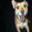
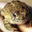
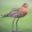
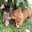
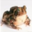
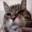
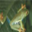
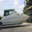
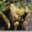
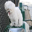
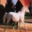
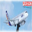
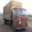
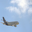
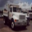
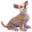
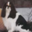
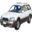
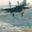
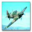
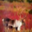
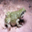
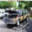

In [11]:
# ===== ВИТРИНА ДЛЯ СДАЧИ: все caption'ы аудита + моя оценка =====
# Картинки вшиваются в вывод (base64) -> на ноутбуке для сдачи всё видно
# без папки artifacts и без запуска ядра.
import base64, html
from IPython.display import HTML, display

_MIME7 = {".jpg": "jpeg", ".jpeg": "jpeg", ".png": "png", ".gif": "gif", ".webp": "webp"}

def _thumb7(path, width=220):
    try:
        mime = _MIME7.get(Path(path).suffix.lower(), "png")
        data = base64.b64encode(Path(path).read_bytes()).decode()
        return f'<img src="data:image/{mime};base64,{data}" style="width:{width}px;border-radius:6px">'
    except Exception:
        return f'<div style="width:{width}px;height:120px;background:#eee;border-radius:6px;padding-top:50px;text-align:center">нет файла</div>'

audit_rows = [json.loads(l) for l in AUDIT_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
done_a = [r for r in audit_rows if r.get("caption_ok") is not None]
ok_a = sum(1 for r in done_a if r["caption_ok"])
err_a = {}
for r in done_a:
    if r["caption_ok"] is False:
        key = r.get("error_type") or "other"
        err_a[key] = err_a.get(key, 0) + 1

print(f"Аудит captions: {len(done_a)}/{len(audit_rows)} | подпись верна: {ok_a} | с ошибкой: {len(done_a) - ok_a}")
print("Типы ошибок:", err_a if err_a else "—")

cards = []
for i, r in enumerate(audit_rows):
    if r.get("caption_ok") is True:    v, col = "CAPTION ВЕРЕН", "#2e7d32"
    elif r.get("caption_ok") is False: v, col = "CAPTION ОШИБОЧЕН", "#c62828"
    else:                              v, col = "НЕ РАЗМЕЧЕНО", "#9e9e9e"
    cls = "класс совпал" if r["vlm_class"] == r["gt_class"] else f'VLM: {r["vlm_class"]} ≠ эталон: {r["gt_class"]}'
    com = f'<div style="color:#555">{html.escape(str(r.get("comment") or ""))}</div>' if r.get("comment") else ""
    cards.append(
        '<div style="display:inline-block;width:230px;vertical-align:top;margin:6px;'
        'border:1px solid #ddd;border-radius:10px;padding:8px;font-size:12px;line-height:1.4">'
        + _thumb7(r["path"], 220) +
        f'<div style="margin-top:6px"><b>{i+1}. {html.escape(str(r["id"]))}</b> · {r["split"]}</div>'
        f'<div>{cls}</div>'
        f'<div style="background:#f5f5f5;border-radius:6px;padding:4px;margin-top:3px"><i>{html.escape(str(r["caption"]))[:150]}</i></div>'
        f'<div style="color:{col};font-weight:bold;margin-top:3px">{v}</div>{com}</div>')
display(HTML("".join(cards)))

### Визуальные признаки для downstream

*Вес: 1 балл.*

**Постановка.** Этап «визуальные признаки для downstream» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Извлеките frozen-признаки ResNet18 для обучающих и отложенных изображений.
2. Сохраните и предъявите признаки ResNet18 train/test.

**Результат.** признаки ResNet18 train/test.

**Критерий принятия.** Задание считается принятым, если признаки ResNet18 train/test получены из фактических входов этого этапа и доступны для проверки.

In [12]:
# ===== Этап 9. Frozen-признаки ResNet18 для всех отобранных изображений =====
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
backbone.fc = nn.Identity()
dev = "cuda" if HAVE_GPU else "cpu"
backbone = backbone.to(dev).eval()
tf = ResNet18_Weights.IMAGENET1K_V1.transforms()

ids   = [m["id"] for m in manifest]
paths = [m["path"] for m in manifest]
feats = []
with torch.no_grad():
    for i in range(0, len(paths), 64):
        batch = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths[i:i+64]]).to(dev)
        feats.append(backbone(batch).cpu().numpy())
feats = np.concatenate(feats).astype(np.float32)

feat_by_id = {mid: feats[i] for i, mid in enumerate(ids)}
np.savez(ARTIFACTS / "features.npz", ids=np.array(ids), features=feats,
         split=np.array([m["split"] for m in manifest]), label=np.array([m["label"] for m in manifest]))
print(f"Признаки: {feats.shape} (ResNet18 frozen, 512-d) -> artifacts/features.npz")

Признаки: (100, 512) (ResNet18 frozen, 512-d) -> artifacts/features.npz


### Классификаторы при равном бюджете

*Вес: 1 балл.*

**Постановка.** Этап «классификаторы при равном бюджете» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Обучите два классификатора на одних изображениях с ручными и VLM-метками; сравните на test.
2. Сохраните и предъявите artifacts/downstream.json и подтверждённый аудит.

**Результат.** artifacts/downstream.json и подтверждённый аудит.

**Критерий принятия.** Задание считается принятым, если artifacts/downstream.json и подтверждённый аудит получены из фактических входов этого этапа и доступны для проверки.

In [13]:
# ===== Этап 10. LogisticRegression: ручные метки vs VLM-метки, сравнение на test =====
from sklearn.linear_model import LogisticRegression

if ANN_PATH.exists():
    recs = {r["id"]: r for r in [json.loads(l) for l in ANN_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]}
    audit_map = {}
    if AUDIT_PATH.exists():
        audit_map = {r["id"]: r for r in [json.loads(l) for l in AUDIT_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]}
    n_audited = sum(1 for r in audit_map.values() if r.get("caption_ok") is not None)
    audit_complete = bool(audit_map) and n_audited == len(audit_map)

    # ОДНИ и те же train-изображения (где VLM дал валидный класс) — меняются только метки
    tr = [m for m in manifest if m["split"] == "train" and m["id"] in recs and recs[m["id"]]["valid"]]
    te = [m for m in manifest if m["split"] == "test"]
    Xtr = np.stack([feat_by_id[m["id"]] for m in tr])
    Xte = np.stack([feat_by_id[m["id"]] for m in te])
    yte = [m["label"] for m in te]
    ytr_gt  = [m["label"] for m in tr]
    ytr_vlm = [CLASSES.index(recs[m["id"]]["parsed"]["class_name"]) for m in tr]

    clf_gt  = LogisticRegression(max_iter=2000).fit(Xtr, ytr_gt)
    clf_vlm = LogisticRegression(max_iter=2000).fit(Xtr, ytr_vlm)
    acc_gt, acc_vlm = clf_gt.score(Xte, yte), clf_vlm.score(Xte, yte)
    agree = float(np.mean(np.array(ytr_gt) == np.array(ytr_vlm)))

    save_json("downstream.json", {
        "classifier": "LogisticRegression on frozen ResNet18 features",
        "n_train_used": len(tr),
        "n_train_dropped_invalid_vlm": sum(1 for m in manifest if m["split"] == "train") - len(tr),
        "n_test": len(te),
        "accuracy_manual_labels": round(acc_gt, 3),
        "accuracy_vlm_labels": round(acc_vlm, 3),
        "delta": round(acc_vlm - acc_gt, 3),
        "train_label_agreement_vlm_vs_manual": round(agree, 3),
        "human_audit_complete": audit_complete, "n_audited": n_audited, "n_audit": len(audit_map),
        "note": "оба классификатора обучены на одних изображениях; отличаются только метки",
    })
    print(f"test accuracy: ручные метки {acc_gt:.2f} vs VLM-метки {acc_vlm:.2f} (Δ={acc_vlm-acc_gt:+.2f})")
    print(f"Согласие меток на train: {agree:.2f} | аудит: {n_audited}/{len(audit_map)} (complete={audit_complete})")
else:
    print("annotations.jsonl нет -> сначала этап 5")

test accuracy: ручные метки 0.50 vs VLM-метки 0.42 (Δ=-0.08)
Согласие меток на train: 0.76 | аудит: 23/23 (complete=True)


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [14]:
# ===== Бонус: влияет ли разрешение входа на качество авто-разметки? =====
# Гипотеза (сформулирована ДО проверки): CIFAR 32x32 слишком мелко для Qwen2.5-VL,
# апскейл до 224px улучшит валидность JSON и точность class_name. Отложенный test
# используется только как материал измерения, гипотеза по нему не подбиралась.
from PIL import Image as PILImage

if RUN_BONUS and HAVE_GPU and ANN_PATH.exists():
    up_dir = ARTIFACTS / "images_up224"; up_dir.mkdir(exist_ok=True)
    picked, seen_c = [], {}
    for m in [m for m in manifest if m["split"] == "test"]:
        seen_c[m["class_name"]] = seen_c.get(m["class_name"], 0) + 1
        if seen_c[m["class_name"]] <= BONUS_PER_CLASS:
            picked.append(m)

    rows = []
    for m in picked:
        up_path = up_dir / f"{m['id']}_up224.png"
        PILImage.open(m["path"]).convert("RGB").resize((224, 224), PILImage.Resampling.LANCZOS).save(up_path)
        rec = {"id": m["id"], "gt": m["class_name"]}
        for tag, p in [("orig32", m["path"]), ("up224", str(up_path))]:
            raw, dt = infer_image(p, PROMPT)
            ann, err = parse_annotation(raw)
            rec[tag] = {"pred": ann.class_name if ann else None, "valid": ann is not None,
                        "correct": bool(ann and ann.class_name == m["class_name"]),
                        "uncertain": bool(ann.uncertain) if ann else None,
                        "latency_s": round(dt, 2), "error": err}
        rows.append(rec)
        print(f"{m['id']}: orig32={rec['orig32']['pred']}({rec['orig32']['correct']}) "
              f"| up224={rec['up224']['pred']}({rec['up224']['correct']})")

    def agg(tag):
        return {"valid": round(sum(r[tag]["valid"] for r in rows) / len(rows), 3),
                "accuracy": round(sum(r[tag]["correct"] for r in rows) / len(rows), 3),
                "median_latency_s": float(np.median([r[tag]["latency_s"] for r in rows]))}
    res = {"n": len(rows), "orig32": agg("orig32"), "up224": agg("up224")}

    md = ("# Бонусное мини-исследование: разрешение входа vs качество авторазметки\n\n"
          "**Гипотеза.** CIFAR-10 хранит изображения 32x32; для Qwen2.5-VL это ниже рабочего разрешения, "
          "поэтому апскейл 32->224 (LANCZOS) должен увеличить валидность JSON и точность class_name "
          "без смены модели и промпта.\n\n"
          f"**Протокол.** {res['n']} test-изображений (по {BONUS_PER_CLASS} на класс), одинаковый промпт и greedy-декодинг, "
          "варианты: исходный 32px и апскейл 224px. Метрики: доля валидных JSON, точность класса, медианная задержка.\n\n"
          f"**Наблюдения.** orig32: valid={res['orig32']['valid']}, acc={res['orig32']['accuracy']}, "
          f"lat={res['orig32']['median_latency_s']}s | up224: valid={res['up224']['valid']}, "
          f"acc={res['up224']['accuracy']}, lat={res['up224']['median_latency_s']}s\n\n"
          f"**Вывод.** {'Апскейл улучшает качество' if res['up224']['accuracy'] > res['orig32']['accuracy'] else 'Существенного выигрыша от апскейла нет'} "
          "на данной выборке (малый n, разброс = +-1 изображение на класс). Подробные записи в artifacts/bonus.json.")
    (ARTIFACTS / "bonus.md").write_text(md, encoding="utf-8")
    save_json("bonus.json", {"hypothesis": "апскейл 32->224 улучшает валидность и точность",
                             "protocol": "одинаковый промпт/greedy, две версии входа", **res, "rows": rows})
    print(f"\nБонус: orig32 acc={res['orig32']['accuracy']}, up224 acc={res['up224']['accuracy']} -> artifacts/bonus.md + bonus.json")
else:
    print("Бонус пропущен (RUN_BONUS=False / нет GPU / нет аннотаций)")

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
c:\Users\eric1\.conda\envs\fmi-cv\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


test_581: orig32=airplane(True) | up224=airplane(True)
test_2404: orig32=airplane(True) | up224=airplane(True)
test_1229: orig32=automobile(True) | up224=automobile(True)
test_2875: orig32=automobile(True) | up224=automobile(True)
test_988: orig32=bird(True) | up224=bird(True)
test_3710: orig32=bird(True) | up224=bird(True)
test_1166: orig32=dog(False) | up224=cat(True)
test_5011: orig32=cat(True) | up224=cat(True)
test_737: orig32=deer(True) | up224=bird(False)
test_4350: orig32=automobile(False) | up224=deer(True)
test_1862: orig32=dog(True) | up224=dog(True)
test_1908: orig32=cat(False) | up224=cat(False)
test_952: orig32=frog(True) | up224=frog(True)
test_3455: orig32=dog(False) | up224=frog(True)
test_2440: orig32=horse(True) | up224=horse(True)
test_3367: orig32=horse(True) | up224=horse(True)
test_6429: orig32=ship(True) | up224=ship(True)
test_6490: orig32=automobile(False) | up224=automobile(False)
test_209: orig32=truck(True) | up224=truck(True)
test_960: orig32=automobile(Fa

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.